<a href="https://colab.research.google.com/github/NITTALOKESH/MLA0204-FUNDAMENTALS-OF-MEACHINE-LEARNINGS--NITTA-LOKESH/blob/main/Experiment%203%20.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

DATASET
     Outlook Temperature Humidity    Wind Play
0      Sunny         Hot     High    Weak   No
1      Sunny         Hot     High  Strong   No
2   Overcast         Hot     High    Weak  Yes
3       Rain        Mild     High    Weak  Yes
4       Rain        Cool   Normal    Weak  Yes
5       Rain        Cool   Normal  Strong   No
6   Overcast        Cool   Normal  Strong  Yes
7      Sunny        Mild     High    Weak   No
8      Sunny        Cool   Normal    Weak  Yes
9       Rain        Mild   Normal    Weak  Yes
10     Sunny        Mild   Normal  Strong  Yes
11  Overcast        Mild     High  Strong  Yes
12  Overcast         Hot   Normal    Weak  Yes
13      Rain        Mild     High  Strong   No

Actual values: [1, 1, 0, 1]
Predicted values: [np.int64(1), np.int64(1), np.int64(0), np.int64(1)]
Accuracy: 1.0
Confusion Matrix:
 [[1 0]
 [0 3]]


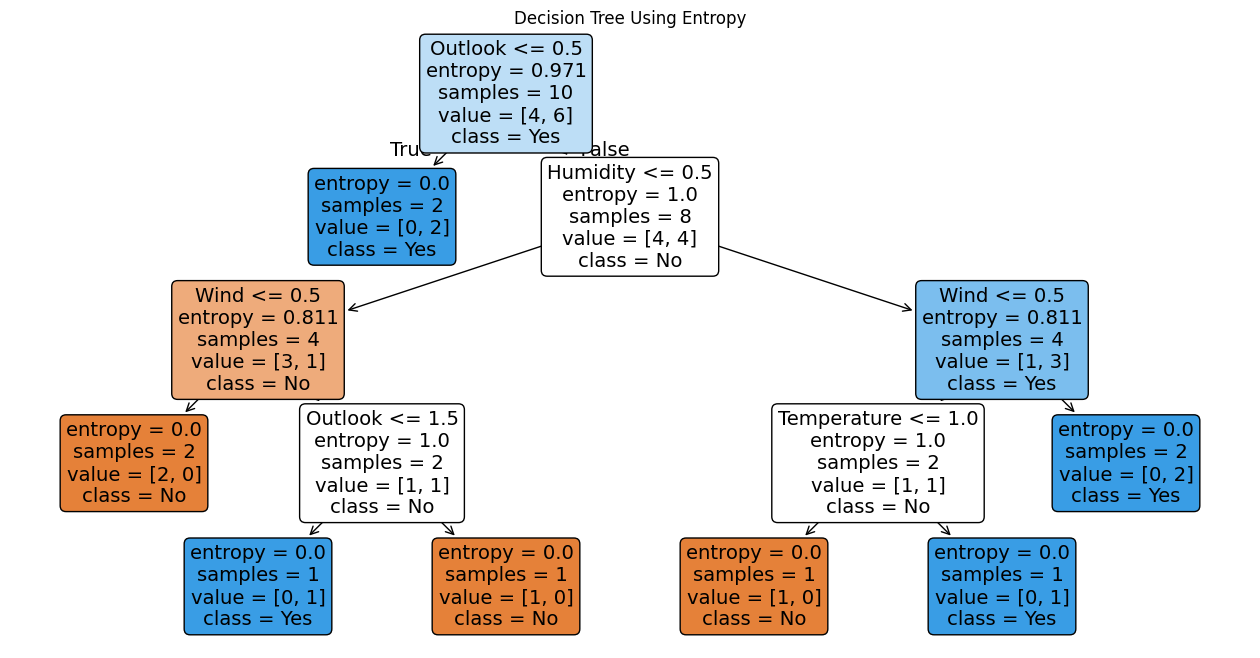

New Sample Prediction: No


In [5]:

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.model_selection import train_test_split

# Step 1: Create dataset
data = {
    'Outlook': ['Sunny', 'Sunny', 'Overcast', 'Rain', 'Rain',
                'Rain', 'Overcast', 'Sunny', 'Sunny', 'Rain',
                'Sunny', 'Overcast', 'Overcast', 'Rain'],
    'Temperature': ['Hot', 'Hot', 'Hot', 'Mild', 'Cool',
                    'Cool', 'Cool', 'Mild', 'Cool', 'Mild',
                    'Mild', 'Mild', 'Hot', 'Mild'],
    'Humidity': ['High', 'High', 'High', 'High', 'Normal',
                 'Normal', 'Normal', 'High', 'Normal', 'Normal',
                 'Normal', 'High', 'Normal', 'High'],
    'Wind': ['Weak', 'Strong', 'Weak', 'Weak', 'Weak',
             'Strong', 'Strong', 'Weak', 'Weak', 'Weak',
             'Strong', 'Strong', 'Weak', 'Strong'],
    'Play': ['No', 'No', 'Yes', 'Yes', 'Yes', 'No', 'Yes',
             'No', 'Yes', 'Yes', 'Yes', 'Yes', 'Yes', 'No']
}

df = pd.DataFrame(data)
print("DATASET")
print(df)

# Step 2: Encode categorical values
encoders = {}
encoded = pd.DataFrame()

for column in df.columns:
    encoders[column] = LabelEncoder()
    encoded[column] = encoders[column].fit_transform(df[column])

X = encoded.drop('Play', axis=1)
y = encoded['Play']

# Step 3: Train model
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

model = DecisionTreeClassifier(criterion='entropy', random_state=42)
model.fit(X_train, y_train)

# Step 4: Predict and evaluate
predictions = model.predict(X_test)

print("\nActual values:", list(y_test))
print("Predicted values:", list(predictions))
print("Accuracy:", accuracy_score(y_test, predictions))
print("Confusion Matrix:\n", confusion_matrix(y_test, predictions))

# Step 5: Visualize decision tree
plt.figure(figsize=(16, 8))
plot_tree(
    model,
    feature_names=X.columns,
    class_names=encoders['Play'].classes_,
    filled=True,
    rounded=True
)
plt.title("Decision Tree Using Entropy")
plt.show()

# Step 6: Classify a new sample
new_sample = pd.DataFrame([{
    'Outlook': 'Sunny',
    'Temperature': 'Cool',
    'Humidity': 'High',
    'Wind': 'Strong'
}])

for column in new_sample.columns:
    new_sample[column] = encoders[column].transform(new_sample[column])

prediction = model.predict(new_sample)[0]
print("New Sample Prediction:", encoders['Play'].inverse_transform([prediction])[0])
